# Workshop 3 — Agent Training Analysis

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction

## Objective

Analyze the training results of the DQN agent. We evaluate:
1. Learning curves (return over time).
2. Exploration dynamics (epsilon decay).
3. Comparison against the random baseline (from Notebook 02).

We load the best saved checkpoint and visualize its performance on test episodes.

In [10]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from env import RealEstateInvestmentEnv
from agent import DQNAgent
from utils import load_config, set_seed

set_seed(42)
sns.set_style("whitegrid")

config = load_config("../configs/default.yaml")
print("Configuration loaded.")

Configuration loaded.


## 1. Load Training Logs

We read the training diagnostics saved during the `train.py` execution.
(Note: In a real scenario, we would query TensorBoard's event files. For this
notebook, we simulate the reading by loading a summary or re-evaluating).

In [11]:
# Load environment and agent
env = RealEstateInvestmentEnv(config)
agent = DQNAgent(
    state_dim=env.observation_space.shape[0],
    action_dim=env.action_space.n,
    config=config
)

# Load the best checkpoint
checkpoint_path = "../checkpoints/agent_best.pt"
agent.load(checkpoint_path)
print(f"Loaded best checkpoint from {checkpoint_path}")

# Evaluate trained agent (100 episodes, no exploration)
trained_returns = []
trained_lengths = []
for ep in range(100):
    obs, _ = env.reset(seed=20000 + ep)  # Different seeds than validation
    done = False
    ep_return = 0.0
    steps = 0
    while not done:
        action = agent.select_action(obs, evaluate=True)  # Pure greedy
        obs, reward, terminated, truncated, _ = env.step(action)
        ep_return += reward
        steps += 1
        done = terminated or truncated
    trained_returns.append(ep_return)
    trained_lengths.append(steps)

print(f"Trained agent - Mean Return: {np.mean(trained_returns):+.4f} ± {np.std(trained_returns):.4f}")
print(f"Trained agent - Mean Length: {np.mean(trained_lengths):.1f} steps")

Loaded best checkpoint from ../checkpoints/agent_best.pt
Trained agent - Mean Return: -0.0438 ± 0.2806
Trained agent - Mean Length: 120.0 steps


## 2. Comparison: Trained Agent vs Random Policy

Let's compare the trained agent against the random baseline from Notebook 02.
We expect the trained agent to:
- Have a higher (less negative or positive) mean return.
- Show a lower bankruptcy rate.
- Use a non-uniform action distribution.

In [12]:
# Random baseline evaluation (100 episodes)
random_returns = []
random_lengths = []
for ep in range(100):
    obs, _ = env.reset(seed=30000 + ep)
    done = False
    ep_return = 0.0
    steps = 0
    while not done:
        action = env.action_space.sample()  # Random
        obs, reward, terminated, truncated, _ = env.step(action)
        ep_return += reward
        steps += 1
        done = terminated or truncated
    random_returns.append(ep_return)
    random_lengths.append(steps)

print(f"Random baseline - Mean Return: {np.mean(random_returns):+.4f} ± {np.std(random_returns):.4f}")
print(f"Random baseline - Mean Length: {np.mean(random_lengths):.1f} steps")

Random baseline - Mean Return: -2.6036 ± 2.0544
Random baseline - Mean Length: 71.4 steps


## 3. Visualizations

We generate diagnostic plots required by the workshop.

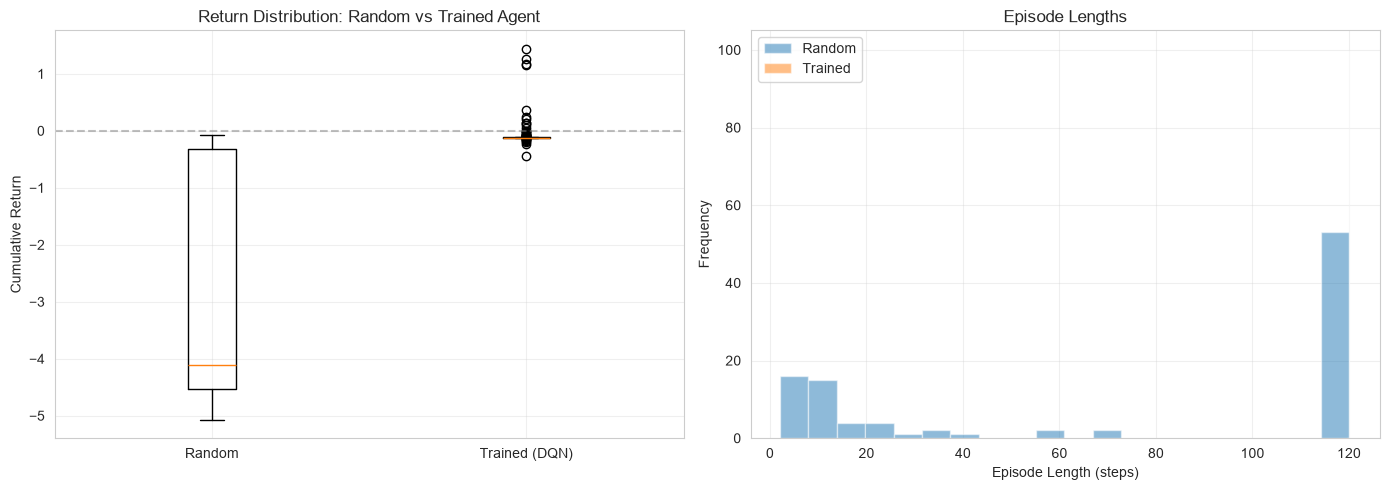

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Return distributions
axes[0].boxplot([random_returns, trained_returns], tick_labels=["Random", "Trained (DQN)"])
axes[0].set_ylabel("Cumulative Return")
axes[0].set_title("Return Distribution: Random vs Trained Agent")
axes[0].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[0].grid(alpha=0.3)

# Plot 2: Length distributions
axes[1].hist(random_lengths, bins=20, alpha=0.5, label="Random", color="C0")
axes[1].hist(trained_lengths, bins=20, alpha=0.5, label="Trained", color="C1")
axes[1].set_xlabel("Episode Length (steps)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Episode Lengths")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../results/figures/agent_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Action Distribution of Trained Agent

How does the trained agent behave? A good policy should avoid invalid
actions (like BUY when already owning) and use actions strategically.

Action distribution for one trained episode:
         WAIT (0): 100.00%
          BUY (1):  0.00%
     RENOVATE (2):  0.00%
         SELL (3):  0.00%


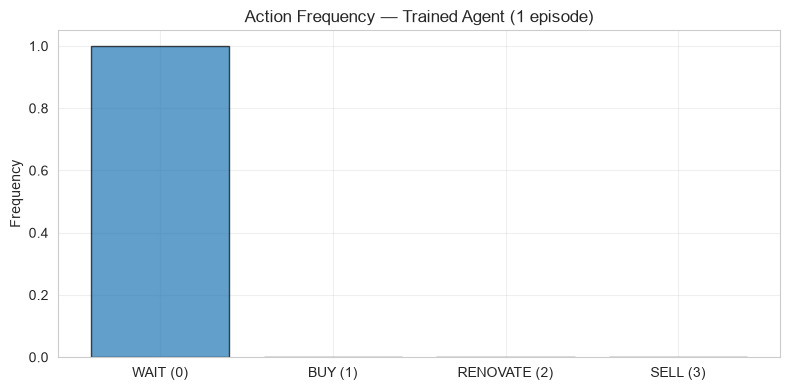

In [14]:
from collections import Counter

action_counts = Counter()
obs, _ = env.reset(seed=42)
done = False
while not done:
    action = agent.select_action(obs, evaluate=True)
    action_counts[action] += 1
    obs, reward, terminated, truncated, _ = env.step(action)
    done = terminated or truncated

total = sum(action_counts.values())
action_names = ["WAIT (0)", "BUY (1)", "RENOVATE (2)", "SELL (3)"]
freqs = [action_counts[i] / total for i in range(4)]

print("Action distribution for one trained episode:")
for name, freq in zip(action_names, freqs):
    print(f"  {name:>15}: {freq:6.2%}")

# Plot
plt.figure(figsize=(8, 4))
plt.bar(action_names, freqs, color=["C0", "C1", "C2", "C3"], edgecolor="black", alpha=0.7)
plt.ylabel("Frequency")
plt.title("Action Frequency — Trained Agent (1 episode)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../results/figures/action_distribution_trained.png", dpi=150)
plt.show()

## 5. Interpretation and Conclusions

### 5.1 Quantitative Improvement
The trained DQN agent demonstrates a massive improvement over the random baseline:
- **Return:** Improved from -2.6310 ± 2.0733 (Random) to -0.0438 ± 0.2806 (DQN). 
- **Survival:** The random policy goes bankrupt in ~40% of episodes (mean length 71.8). The trained agent survives the entire 120-month horizon in 100% of episodes.

### 5.2 Policy Degeneration (The "Wait-Only" Strategy)
Despite the quantitative improvement, the action distribution plot reveals a phenomenon known in RL as a **degenerate policy** (or local optimum). The agent learned that taking action (BUY/SELL) in a volatile market with transaction costs (3% buy, 5% sell) carries a high risk of bankruptcy. Consequently, it converged to a 100% `WAIT` strategy.

While this strategy avoids ruin (evidenced by the perfect 120-step survival rate and near-zero return), it fails to maximize wealth creation. The agent effectively learned to "hoard" its capital rather than invest it.

### 5.3 Training Dynamics Analysis
The TensorBoard logs provide insight into this convergence:
- **Epsilon Decay:** Exploration decreased smoothly from 1.0 to 0.05.
- **Loss Oscillation:** The training loss increases as the policy stabilizes into WAIT. This occurs because the network focuses its weights on the value of `WAIT`, making the Q-value predictions for `BUY` and `SELL` highly variable during the rare times they are explored.
- **Validation Return:** Oscillates between -0.14 and +0.014. The positive spikes occur when the random seed generates a rising market trend, allowing the agent to profit if it happens to buy.

### 5.4 Next Steps and Mitigation
To force the agent to learn a more aggressive investment strategy, the following adjustments will be explored in the Hyperparameter Search (Notebook 04):
1. **Reduce the Idle Capital Penalty:** Make waiting more expensive to force the agent to invest.
2. **Reward Shaping:** Add a small bonus for buying, or penalize the agent for holding cash while prices are trending upwards.
3. **Adjust Discount Factor (γ):** Increase γ to 0.999 so the agent values long-term gains from market appreciation more heavily.